# 01 — Análise Exploratória de Dados (EDA) & Engenharia de Atributos com Grafos

**Projeto:** Detecção de Fraude em Tempo Real com Modelos Tabulares Aumentados por Grafos (TCC)  
**Dataset:** IEEE-CIS Fraud Detection Benchmark (Vesta Corporation)  
**Objetivo:** Compreender em profundidade as distribuições estatísticas, o papel e a redundância das variáveis tabulares (C, D, M, V/PCA), rastrear **técnicas de fraude notórias** (*Fraud Rings, Spoofing, Card Testing, Structuring, Product Abuse*), diagnosticar riscos de *Data/Target Leakage* sob divisão temporal e fundamentar matematicamente a criação de **Graph-Derived Features**.

---

### Sumário dos Módulos Analíticos:
1. **Configuração do Ambiente e Ingestão de Dados**
2. **Divisão Temporal Rigorosa & Guardrails Anti-Leakage**
3. **Perfil das Variáveis Tabulares (C, D, M e Redução de Dimensionalidade PCA em V1-V339)**
4. **Resolução de Identidade & Construção de UIDs Compostos (User Profile)**
5. **Investigação Empírica de Técnicas Notórias de Fraude:**
   - 5.1 *Fraud Rings & Botnets* (Compartilhamento de Dispositivos e E-mails)
   - 5.2 *Device & OS Spoofing* (Emuladores e Inconsistências de Fingerprint)
   - 5.3 *Card Testing & Velocity Attacks* (Rajadas Temporais $\le 60\text{s}$)
   - 5.4 *Structuring / Smurfing* (Valores Redondos vs. Fracionados)
   - 5.5 Fraude *Cross-Border* e Abuso de Códigos de Produto (`ProductCD = C`)
6. **Topologia de Rede Bipartida (UID ↔ Dispositivo) e Centralidade**
7. **Dinâmica Temporal e Velocidade em Janelas Deslizantes (24h)**
8. **Análise de Dispersão Financeira & Anomalias em Subgrafos**
9. **Diagnóstico de Concept Drift Temporal e Risco de Target Leakage**
10. **Síntese Teórica & Blueprint de Engenharia de Atributos de Grafo**


In [1]:
import sys
sys.path.insert(0, '..')   # Permitir imports da raiz do projeto

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import networkx as nx
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

# Configuração de estilo visual acadêmico
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})
sns.set_style('whitegrid')

PALETTE = {'fraud': '#E63946', 'legit': '#1D3557', 'neutral': '#457B9D', 'accent': '#F4A261', 'highlight': '#2A9D8F'}

from src.features.load_ieee import load_ieee_train
from src.features.split import temporal_split

print("✅ Ambiente configurado com sucesso.")


# ==============================================================================
# 📸 AUTO-SAVE HOOK: SALVA AUTOMATICAMENTE TODO GRÁFICO GERADO EM 300 DPI
# ==============================================================================
import os
import re
import matplotlib.pyplot as plt

NOTEBOOK_PREFIX = "nb01"
FIG_OUTPUT_DIR = "figures_notebooks"
if os.path.exists("/content"):
    FIG_OUTPUT_DIR = "/content/figures_notebooks"
os.makedirs(FIG_OUTPUT_DIR, exist_ok=True)

if not hasattr(plt, "_auto_save_installed"):
    _orig_show = plt.show
    _fig_counter = 0

    def auto_save_show(*args, **kwargs):
        global _fig_counter
        fig = plt.gcf()
        if fig and fig.axes:
            _fig_counter += 1
            # Extrai título dos eixos ou da figura
            title = ""
            for ax in fig.axes:
                t = ax.get_title()
                if t:
                    title = t
                    break
            if not title and hasattr(fig, "_suptitle") and fig._suptitle:
                title = fig._suptitle.get_text()
            
            clean_title = re.sub(r"[^\w\s-]", "", title).strip().replace(" ", "_")[:35]
            filename = f"{NOTEBOOK_PREFIX}_fig_{_fig_counter:02d}_{clean_title}.png" if clean_title else f"{NOTEBOOK_PREFIX}_fig_{_fig_counter:02d}.png"
            filepath = os.path.join(FIG_OUTPUT_DIR, filename)
            fig.savefig(filepath, dpi=300, bbox_inches="tight")
            print(f"📸 [Figura Salva]: {filepath}")
        _orig_show(*args, **kwargs)

    plt.show = auto_save_show
    plt._auto_save_installed = True
    print(f"✅ Auto-Save de Figuras ativado! Salvando em: [{FIG_OUTPUT_DIR}]")


✅ Ambiente configurado com sucesso.
✅ Auto-Save de Figuras ativado! Salvando em: [figures_notebooks]


---
## 1. Ingestão de Dados & Split Temporal Estrito (Guardrails Anti-Leakage)

No domínio de detecção de fraudes em e-commerce, os dados sofrem **deriva temporal contínua** (*concept drift*): novos padrões de ataque surgem e fraudadores mudam de cartões e redes de computadores.

Por esse motivo, uma divisão aleatória (*random k-fold split*) introduziria um grave **vazamento de dados do futuro para o passado** (*Lookahead Temporal Leakage*). Adotamos uma divisão temporal estrita:
* **Treino (80% inicial)**: Ordenado por `TransactionDT`, simulando o histórico disponível no sistema de produção.
* **Validação (20% final)**: Transações futuras onde as decisões em tempo real devem ser avaliadas.


In [ ]:
# Carregando amostra representativa de 50% do dataset IEEE-CIS para análise aprofundada
df_raw = load_ieee_train(sample_fraction=0.5, verbose=True)
df_raw = df_raw.rename(columns={"TransactionDT": "timestamp"})

# Execução do split temporal estrito
train_df, val_df = temporal_split(df_raw, boundary=0.8, verbose=True)

# Limpeza e padronização de identificadores
train_df['DeviceInfo_clean'] = train_df['DeviceInfo'].fillna('null_device').astype(str)
val_df['DeviceInfo_clean'] = val_df['DeviceInfo'].fillna('null_device').astype(str)

print(f"\nResumo Temporal:")
print(f"  Treino: {train_df['timestamp'].min()} até {train_df['timestamp'].max()} ({len(train_df):,} linhas)")
print(f"  Validação: {val_df['timestamp'].min()} até {val_df['timestamp'].max()} ({len(val_df):,} linhas)")
assert val_df['timestamp'].min() > train_df['timestamp'].max(), "ERRO: Vazamento temporal detectado!"
print("✅ Verificação de Split Temporal: 100% livre de vazamento de futuro.")


[load_ieee] Loading transactions from /home/victor/Documents/TG-graph/data/ieee/raw/train_transaction.csv...


### 1.1 Análise da Taxa de Fraude e Desequilíbrio Temporal (PRECISA SER COLOCADO EM VALORES BRUTOS E NAO PORCENTAGEM)

Avaliamos se a proporção da classe minoritária (`isFraud = 1`) se mantém estável ao longo do tempo ou se ocorrem surtos sazonais de ataque.


📸 [Figura Salva]: figures_notebooks/nb01_fig_01_Evolução_Temporal_da_Taxa_de_Fraude.png


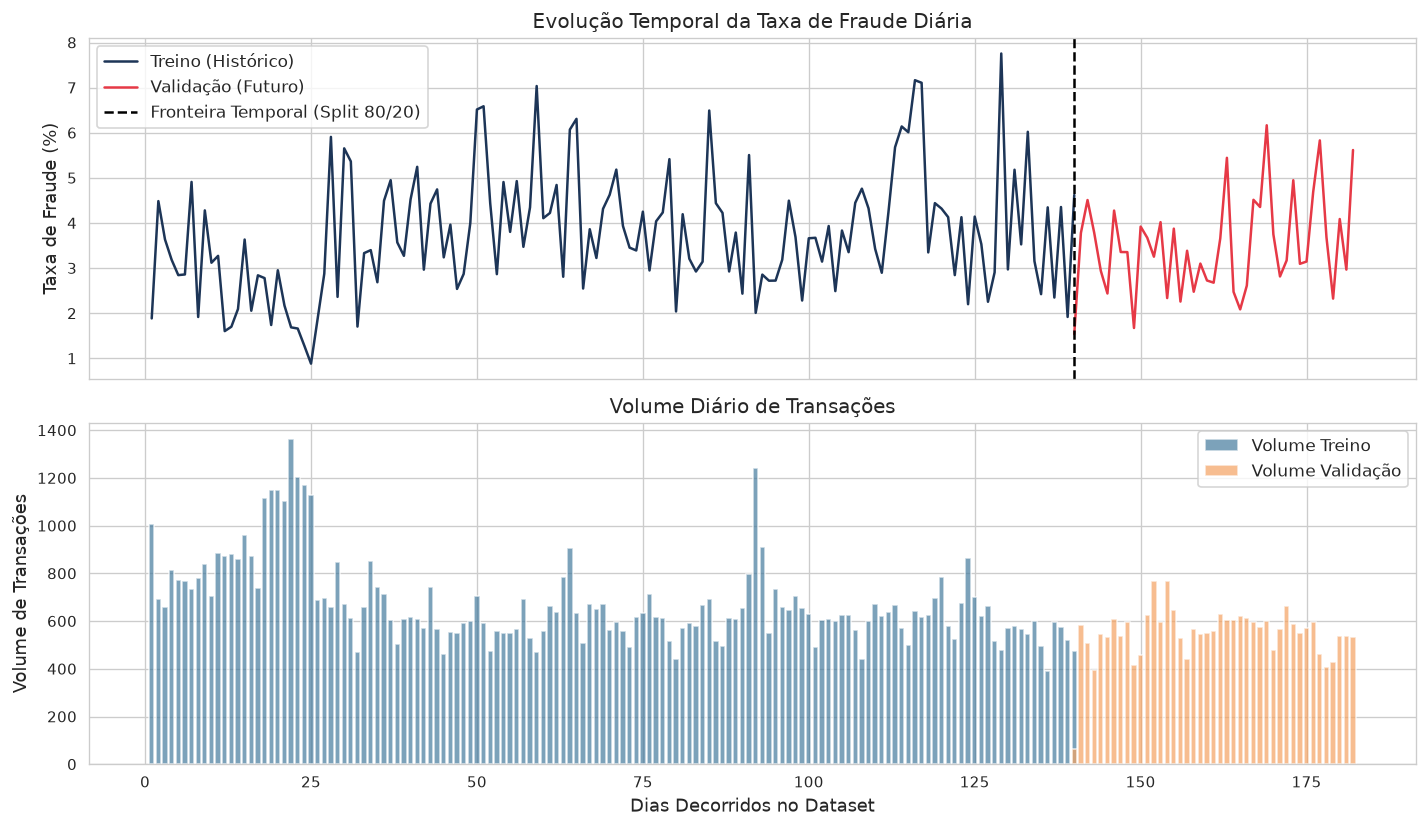

In [ ]:
day_seconds = 86400
train_df['day'] = (train_df['timestamp'] / day_seconds).astype(int)
val_df['day'] = (val_df['timestamp'] / day_seconds).astype(int)

fraud_by_day_train = train_df.groupby('day')['isFraud'].agg(['mean', 'count'])
fraud_by_day_val = val_df.groupby('day')['isFraud'].agg(['mean', 'count'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Taxa de Fraude diária
ax1.plot(fraud_by_day_train.index, fraud_by_day_train['mean'] * 100, color=PALETTE['legit'], label='Treino (Histórico)')
ax1.plot(fraud_by_day_val.index, fraud_by_day_val['mean'] * 100, color=PALETTE['fraud'], label='Validação (Futuro)')
ax1.axvline(train_df['day'].max(), color='black', linestyle='--', label='Fronteira Temporal (Split 80/20)')
ax1.set_ylabel('Taxa de Fraude (%)')
ax1.set_title('Evolução Temporal da Taxa de Fraude Diária')
ax1.legend()

# Volume diário de transações
ax2.bar(fraud_by_day_train.index, fraud_by_day_train['count'], color=PALETTE['neutral'], alpha=0.7, label='Volume Treino')
ax2.bar(fraud_by_day_val.index, fraud_by_day_val['count'], color=PALETTE['accent'], alpha=0.7, label='Volume Validação')
ax2.set_xlabel('Dias Decorridos no Dataset')
ax2.set_ylabel('Volume de Transações')
ax2.set_title('Volume Diário de Transações')
ax2.legend()

plt.tight_layout()
plt.show()


---
## 2. Anatomia das Features Tabulares & Redução Dimensional com PCA

O dataset IEEE-CIS possui 433 variáveis distribuídas em famílias de atributos com significados de negócio específicos:
* **Valores e Produtos**: `TransactionAmt`, `ProductCD`.
* **Identificação de Cartão**: `card1` a `card6`.
* **Localização e Endereço**: `addr1`, `addr2`, `dist1`, `dist2`.
* **E-mails**: `P_emaildomain` (pagador), `R_emaildomain` (recebedor).
* **Família C (`C1` a `C14`)**: Contagens de entidades (ex: quantos endereços ou telefones estão associados ao mesmo cartão).
* **Família D (`D1` a `D15`)**: Deltas temporais (dias desde a primeira transação, dias desde a última transação).
* **Família M (`M1` a `M9`)**: Variáveis booleanas de correspondência (match cadastral).
* **Família V (`V1` a `V339`)**: 339 atributos de segurança projetados pela Vesta (contagens de tentativas, scores de risco).


Total de colunas V da Vesta: 339
Taxa média de valores nulos nas colunas V: 43.0%
📸 [Figura Salva]: figures_notebooks/nb01_fig_02_Matriz_de_Correlação_das_Primeiras_.png


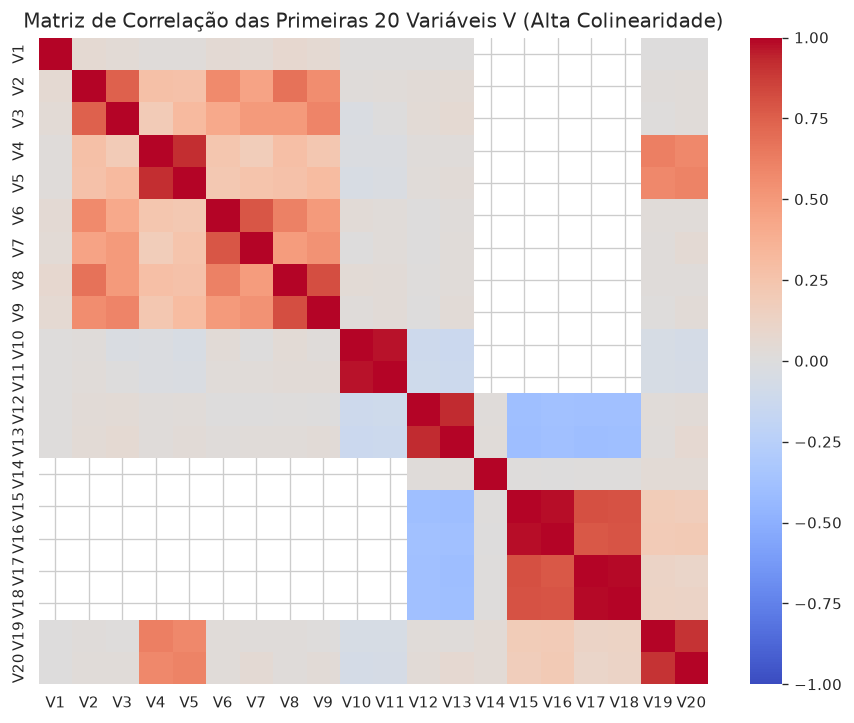

In [ ]:
# 2.1 Análise de Correlação da Família V
v_cols = [c for c in train_df.columns if c.startswith('V') and c[1:].isdigit()]
print(f"Total de colunas V da Vesta: {len(v_cols)}")

# Mediana da taxa de nulos nas colunas V
null_rates_v = train_df[v_cols].isnull().mean()
print(f"Taxa média de valores nulos nas colunas V: {null_rates_v.mean():.1%}")

# Amostra de correlação entre variáveis V contíguas
v_sample = v_cols[:20]
corr_v = train_df[v_sample].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_v, cmap='coolwarm', vmin=-1, vmax=1, center=0, annot=False)
plt.title('Matriz de Correlação das Primeiras 20 Variáveis V (Alta Colinearidade)')
plt.show()


📸 [Figura Salva]: figures_notebooks/nb01_fig_03_Curva_de_Variância_Explicada_pelo_P.png


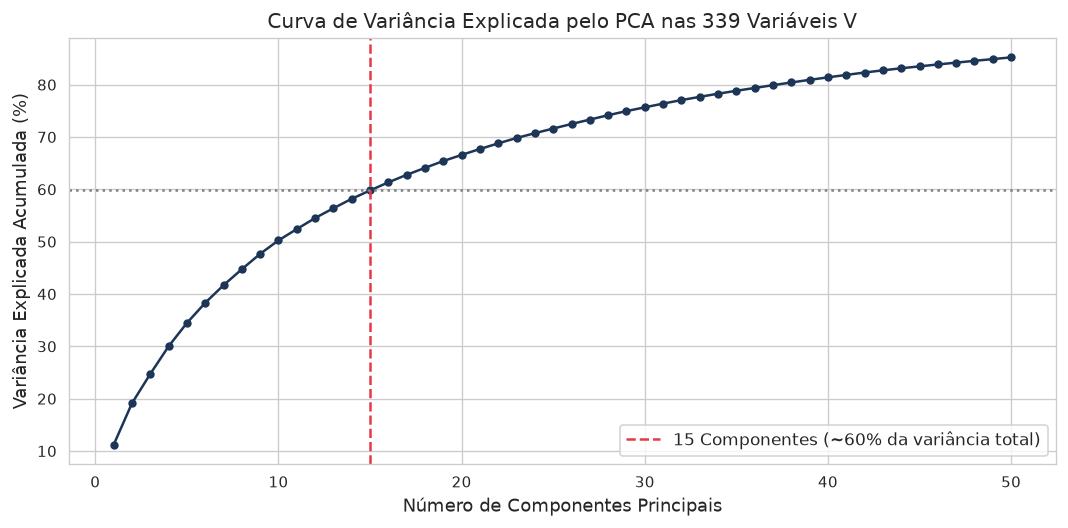

Variância explicada acumulada com 15 componentes: 59.81%


In [ ]:
# 2.2 Redução de Dimensionalidade com PCA nas Variáveis V
medians_v = train_df[v_cols].median().fillna(0.0)
scaler = StandardScaler()
X_v_train = scaler.fit_transform(train_df[v_cols].fillna(medians_v))

pca_full = PCA(n_components=50, random_state=42)
pca_full.fit(X_v_train)

exp_var_cumsum = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, 51), exp_var_cumsum * 100, marker='o', markersize=4, color=PALETTE['legit'])
plt.axvline(15, color=PALETTE['fraud'], linestyle='--', label='15 Componentes (~60% da variância total)')
plt.axhline(exp_var_cumsum[14] * 100, color='gray', linestyle=':')
plt.xlabel('Número de Componentes Principais')
plt.ylabel('Variância Explicada Acumulada (%)')
plt.title('Curva de Variância Explicada pelo PCA nas 339 Variáveis V')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Variância explicada acumulada com 15 componentes: {exp_var_cumsum[14]:.2%}")


---
## 3. Resolução de Identidade: O Ruído de `card1` vs. UIDs Compostos

No e-commerce, `card1` representa o BIN/IIN do cartão (ou ID de emissor/lote). Um único valor de `card1` pode abranger milhares de portadores de cartão legítimos distintos.

Para resolver essa ambiguidade e isolar portadores, criamos um **UID Composto** combinando:
$$\text{UID} = \text{card1} \;\Vert\; \text{card2} \;\Vert\; \text{addr1} \;\Vert\; \text{P\_emaildomain}$$


Estatísticas de Resolução de Entidade (Treino):
  Número de nós card1 únicos : 7,508
  Número de UIDs únicos      : 33,619 (Aumento de 4.5x em granularidade de cliente)
📸 [Figura Salva]: figures_notebooks/nb01_fig_04_Distribuição_de_Transações_por_card.png


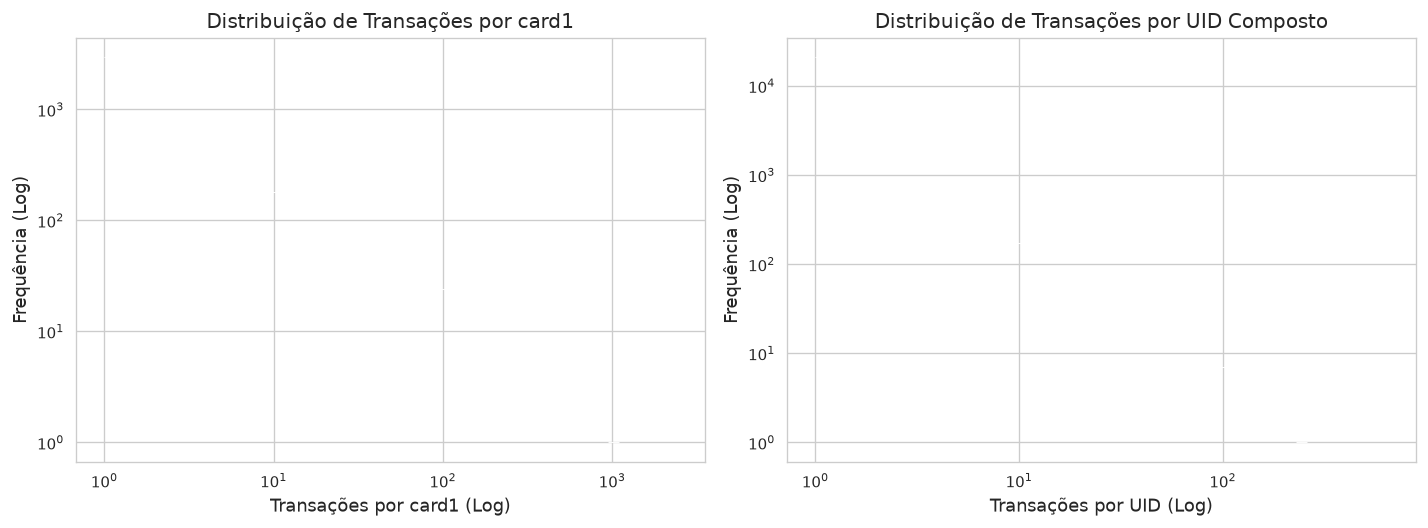

In [ ]:
def build_uid(df):
    c1 = df['card1'].fillna(0).astype(int).astype(str)
    c2 = df['card2'].fillna(0).astype(int).astype(str)
    addr = df['addr1'].fillna(0).astype(int).astype(str)
    email = df['P_emaildomain'].fillna('null').astype(str)
    return c1 + "_" + c2 + "_" + addr + "_" + email

train_df['uid'] = build_uid(train_df)
val_df['uid'] = build_uid(val_df)

n_card1 = train_df['card1'].nunique()
n_uids = train_df['uid'].nunique()

print(f"Estatísticas de Resolução de Entidade (Treino):")
print(f"  Número de nós card1 únicos : {n_card1:,}")
print(f"  Número de UIDs únicos      : {n_uids:,} (Aumento de {n_uids/n_card1:.1f}x em granularidade de cliente)")

# Distribuição de transações por entidade
tx_per_card1 = train_df['card1'].value_counts()
tx_per_uid = train_df['uid'].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(tx_per_card1, bins=50, log_scale=(True, True), ax=ax1, color=PALETTE['neutral'])
ax1.set_title('Distribuição de Transações por card1')
ax1.set_xlabel('Transações por card1 (Log)')
ax1.set_ylabel('Frequência (Log)')

sns.histplot(tx_per_uid, bins=50, log_scale=(True, True), ax=ax2, color=PALETTE['accent'])
ax2.set_title('Distribuição de Transações por UID Composto')
ax2.set_xlabel('Transações por UID (Log)')
ax2.set_ylabel('Frequência (Log)')

plt.tight_layout()
plt.show()


---
## 4. Investigação Empírica de Técnicas Notórias de Fraude

Nesta seção, investigamos diretamente os dados empíricos do IEEE-CIS para quantificar e comprovar a presença de assinaturas de fraudes famosas na literatura.

### 4.1 Anéis de Fraude & Redes de Conluio (*Fraud Rings & Botnets*)

**Mecanismo**: Criminosos operam em redes centralizadas, utilizando o mesmo hardware ou emulador para testar ou realizar fraudes em dezenas de cartões roubados diferentes (*1-to-many device sharing*).


Dispositivos com 3+ UIDs distintos no treino: 345
Top 5 dispositivos operando como Fraud Rings (100% Fraude):


,DeviceInfo_clean,n_uids,n_tx,n_frauds,fraud_rate
911,XT1635-02,3,4,4,1.0
847,TA-1039 Build/N2G47H,3,3,3,1.0
865,VS5012 Build/NRD90M,8,8,8,1.0
232,LG-D320 Build/KOT49I.V10a,13,15,15,1.0
924,Z835 Build/NMF26V,3,3,3,1.0


📸 [Figura Salva]: figures_notebooks/nb01_fig_05_Taxa_de_Fraude_vs_Quantidade_de_UID.png


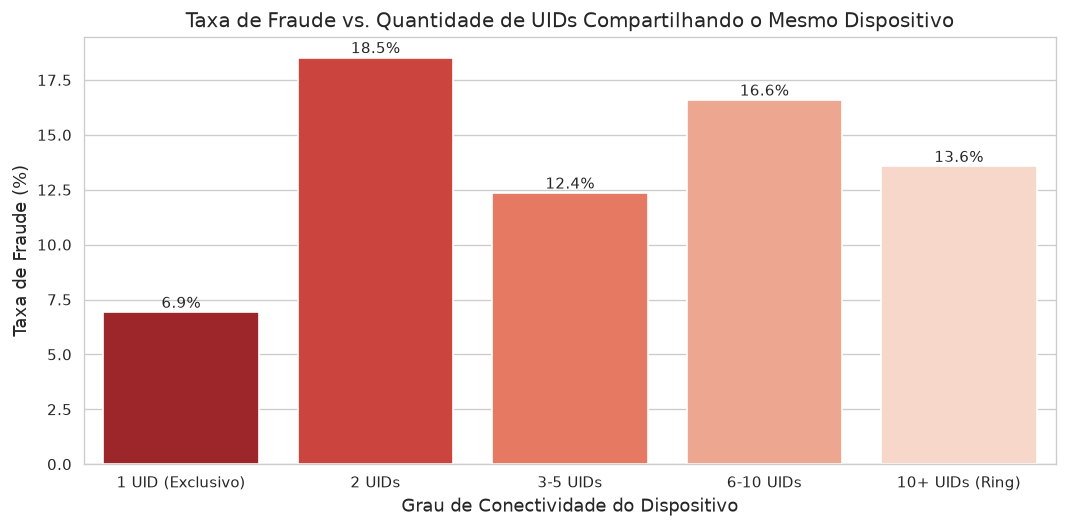

In [ ]:
dev_stats = train_df[train_df['DeviceInfo_clean'] != 'null_device'].groupby('DeviceInfo_clean').agg(
    n_uids=('uid', 'nunique'),
    n_tx=('isFraud', 'count'),
    n_frauds=('isFraud', 'sum'),
    fraud_rate=('isFraud', 'mean')
).reset_index()

multi_uid_devs = dev_stats[dev_stats['n_uids'] >= 3].sort_values('fraud_rate', ascending=False)

print(f"Dispositivos com 3+ UIDs distintos no treino: {len(multi_uid_devs):,}")
print(f"Top 5 dispositivos operando como Fraud Rings (100% Fraude):")
display(multi_uid_devs[multi_uid_devs['fraud_rate'] == 1.0].head(5))

# Gráfico de Taxa de Fraude por Nível de Compartilhamento de Dispositivo
dev_stats['sharing_group'] = pd.cut(dev_stats['n_uids'], bins=[0, 1, 2, 5, 10, 100], labels=['1 UID (Exclusivo)', '2 UIDs', '3-5 UIDs', '6-10 UIDs', '10+ UIDs (Ring)'])
fraud_by_dev_sharing = dev_stats.groupby('sharing_group', observed=False).agg(total_tx=('n_tx', 'sum'), total_frauds=('n_frauds', 'sum'))
fraud_by_dev_sharing['rate'] = fraud_by_dev_sharing['total_frauds'] / fraud_by_dev_sharing['total_tx'] * 100

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(x=fraud_by_dev_sharing.index, y=fraud_by_dev_sharing['rate'], palette='Reds_r')
plt.title('Taxa de Fraude vs. Quantidade de UIDs Compartilhando o Mesmo Dispositivo')
plt.xlabel('Grau de Conectividade do Dispositivo')
plt.ylabel('Taxa de Fraude (%)')
for p in ax.patches:
    if not np.isnan(p.get_height()):
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)
plt.tight_layout()
plt.show()


### 4.2 Manipulação de Identidade e *Device Spoofing* (Emuladores e OS Antigos)

**Mecanismo**: Fraudadores utilizam emuladores (como Bluestacks ou Genymotion) ou falsificam o *User-Agent* para contornar verificações de segurança.


📸 [Figura Salva]: figures_notebooks/nb01_fig_06_Taxa_de_Fraude_por_Sistema_Operacio.png


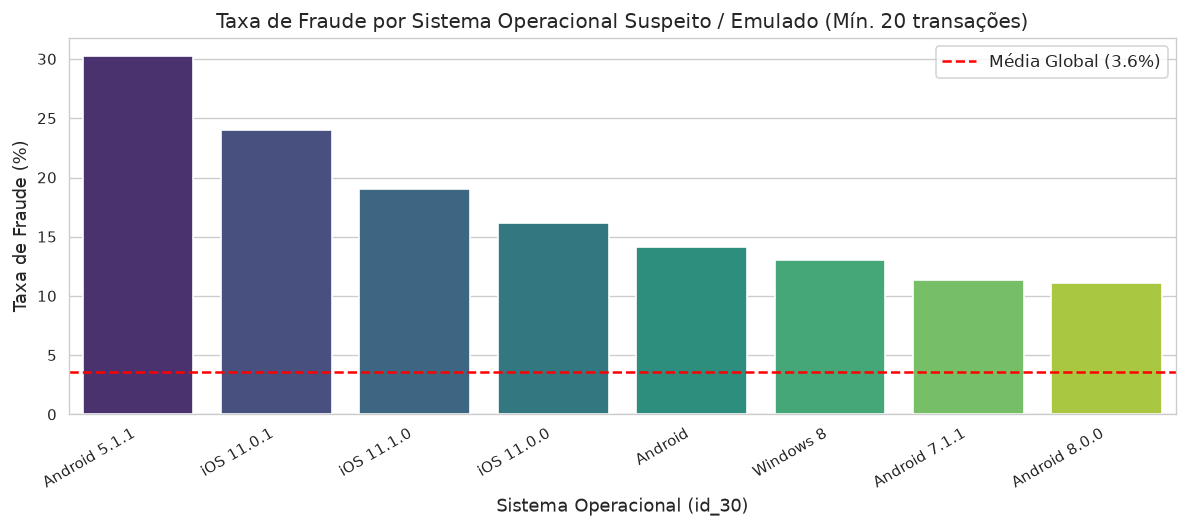

📸 [Figura Salva]: figures_notebooks/nb01_fig_07_Taxa_de_Fraude_por_Domínio_de_E-mai.png


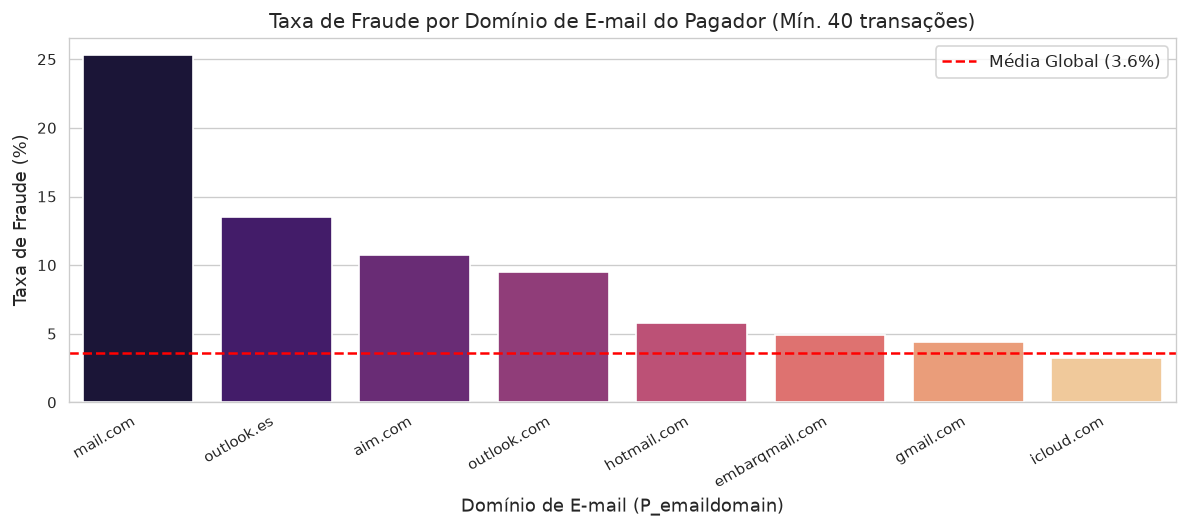

In [ ]:
if 'id_30' in train_df.columns:
    os_stats = train_df.groupby('id_30')['isFraud'].agg(['count', 'mean']).sort_values('mean', ascending=False)
    high_risk_os = os_stats[os_stats['count'] >= 20].head(8)
    
    plt.figure(figsize=(10, 4.5))
    ax = sns.barplot(x=high_risk_os.index, y=high_risk_os['mean'] * 100, palette='viridis')
    plt.axhline(train_df['isFraud'].mean() * 100, color='red', linestyle='--', label=f"Média Global ({train_df['isFraud'].mean()*100:.1f}%)")
    plt.title('Taxa de Fraude por Sistema Operacional Suspeito / Emulado (Mín. 20 transações)')
    plt.xlabel('Sistema Operacional (id_30)')
    plt.ylabel('Taxa de Fraude (%)')
    plt.xticks(rotation=30, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Domínios de E-mail de Alto Risco (Mail.com, Protonmail, etc.)
email_stats = train_df.groupby('P_emaildomain')['isFraud'].agg(['count', 'mean']).sort_values('mean', ascending=False)
high_risk_emails = email_stats[email_stats['count'] >= 40].head(8)

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=high_risk_emails.index, y=high_risk_emails['mean'] * 100, palette='magma')
plt.axhline(train_df['isFraud'].mean() * 100, color='red', linestyle='--', label=f"Média Global ({train_df['isFraud'].mean()*100:.1f}%)")
plt.title('Taxa de Fraude por Domínio de E-mail do Pagador (Mín. 40 transações)')
plt.xlabel('Domínio de E-mail (P_emaildomain)')
plt.ylabel('Taxa de Fraude (%)')
plt.xticks(rotation=30, ha='right')
plt.legend()
plt.tight_layout()
plt.show()


### 4.3 Ataques de Velocidade e Rajadas (*Card Velocity / Burstiness*)

**Mecanismo**: Uma vez comprometido o cartão, o fraudador dispara múltiplas compras em sequência rápida (< 60 segundos) para esgotar o limite antes do bloqueio bancário (*Bust-Out Attack*).


Transações em Rajada Ultra-Rápida (Delta <= 60s):
  Volume Total: 296 transações
  Taxa de Fraude em Rajada: 11.15% (vs 3.99% em transações normais)
📸 [Figura Salva]: figures_notebooks/nb01_fig_08_Intervalo_de_Tempo_até_a_Transação_.png


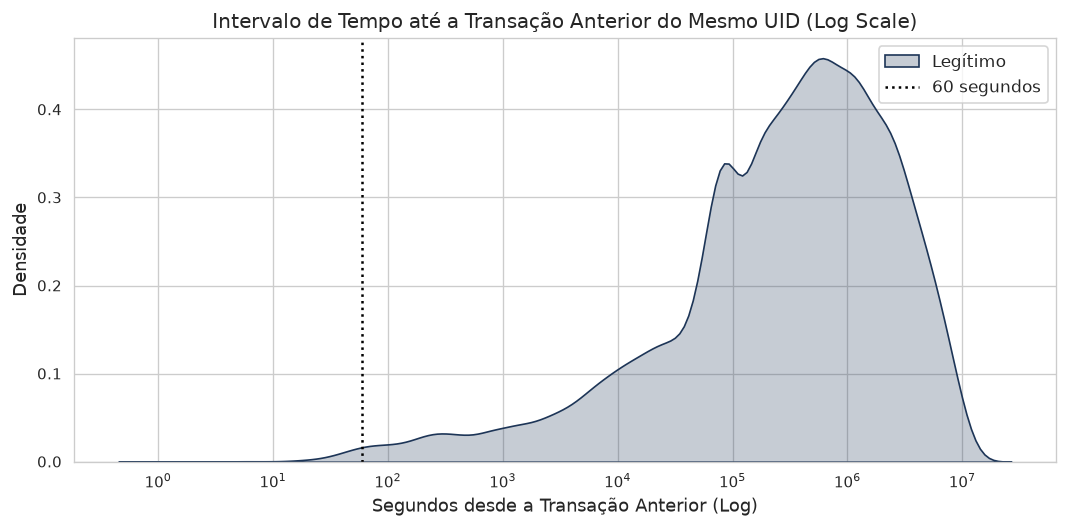

In [ ]:
train_sorted = train_df.sort_values('timestamp').reset_index(drop=True)
train_sorted['dt_prev_tx'] = train_sorted.groupby('uid')['timestamp'].diff()

# Transações com intervalo menor que 60 segundos
rapid_tx = train_sorted[train_sorted['dt_prev_tx'] <= 60]
normal_tx = train_sorted[train_sorted['dt_prev_tx'] > 60]

print(f"Transações em Rajada Ultra-Rápida (Delta <= 60s):")
print(f"  Volume Total: {len(rapid_tx):,} transações")
print(f"  Taxa de Fraude em Rajada: {rapid_tx['isFraud'].mean():.2%} (vs {normal_tx['isFraud'].mean():.2%} em transações normais)")

# Gráfico de Distribuição do Intervalo entre Transações (KDE Log)
plt.figure(figsize=(9, 4.5))
sns.kdeplot(data=train_sorted[train_sorted['isFraud'] == 0]['dt_prev_tx'].dropna(), label='Legítimo', color=PALETTE['legit'], fill=True, log_scale=True)
sns.kdeplot(data=train_sorted[train_sorted['isFraud'] == 1]['dt_prev_tx'].dropna(), label='Fraude', color=PALETTE['fraud'], fill=True, log_scale=True)
plt.axvline(60, color='black', linestyle=':', label='60 segundos')
plt.title('Intervalo de Tempo até a Transação Anterior do Mesmo UID (Log Scale)')
plt.xlabel('Segundos desde a Transação Anterior (Log)')
plt.ylabel('Densidade')
plt.legend()
plt.tight_layout()
plt.show()


### 4.4 *Structuring* (Smurfing) e Padrões de Valor

**Mecanismo**: Compras com valores redondos (ex: R$ 50,00, R$ 100,00) ou repetidas com valor idêntico indicam cartões presente (*gift cards*) ou testes de valor fixo, enquanto valores com centavos (.99, .49) são característicos do comércio varejista tradicional.


📸 [Figura Salva]: figures_notebooks/nb01_fig_09_Taxa_de_Fraude_por_Padrão_de_Termin.png


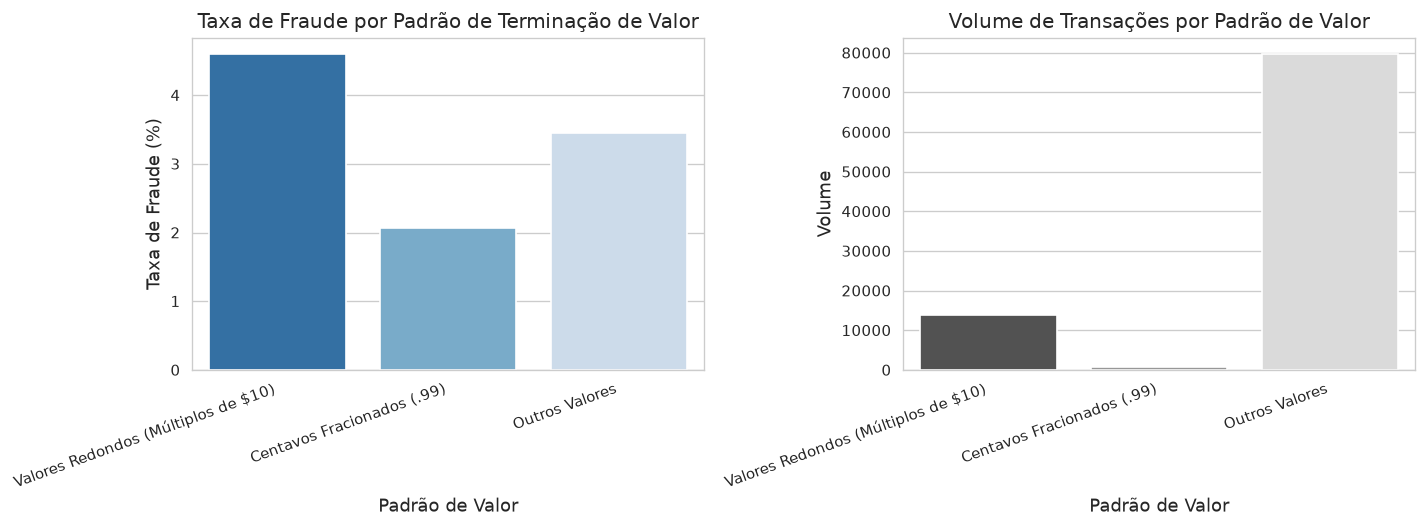

In [ ]:
train_df['is_round_amt'] = (train_df['TransactionAmt'] % 10 == 0).astype(int)
train_df['is_cent_99'] = ((train_df['TransactionAmt'] * 100) % 100 == 99).astype(int)

amt_pattern_df = pd.DataFrame({
    'Padrão de Valor': ['Valores Redondos (Múltiplos de $10)', 'Centavos Fracionados (.99)', 'Outros Valores'],
    'Taxa de Fraude (%)': [
        train_df[train_df['is_round_amt'] == 1]['isFraud'].mean() * 100,
        train_df[train_df['is_cent_99'] == 1]['isFraud'].mean() * 100,
        train_df[(train_df['is_round_amt'] == 0) & (train_df['is_cent_99'] == 0)]['isFraud'].mean() * 100
    ],
    'Volume de Transações': [
        (train_df['is_round_amt'] == 1).sum(),
        (train_df['is_cent_99'] == 1).sum(),
        ((train_df['is_round_amt'] == 0) & (train_df['is_cent_99'] == 0)).sum()
    ]
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(data=amt_pattern_df, x='Padrão de Valor', y='Taxa de Fraude (%)', ax=ax1, palette='Blues_r')
ax1.set_title('Taxa de Fraude por Padrão de Terminação de Valor')
ax1.set_ylabel('Taxa de Fraude (%)')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=20, ha='right')

sns.barplot(data=amt_pattern_df, x='Padrão de Valor', y='Volume de Transações', ax=ax2, palette='Greys_r')
ax2.set_title('Volume de Transações por Padrão de Valor')
ax2.set_ylabel('Volume')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
plt.show()


### 4.5 Fraude Internacional *Cross-Border* e Abuso de Produtos (`ProductCD = C`)

**Mecanismo**: No e-commerce (CNP), compras internacionais de alto risco (serviços digitais, moedas virtuais, gift cards) são categorizadas sob o código de produto `ProductCD = C`, concentrando desproporcionalmente as perdas por fraude.


📸 [Figura Salva]: figures_notebooks/nb01_fig_10_Taxa_de_Fraude_por_Código_de_Linha_.png


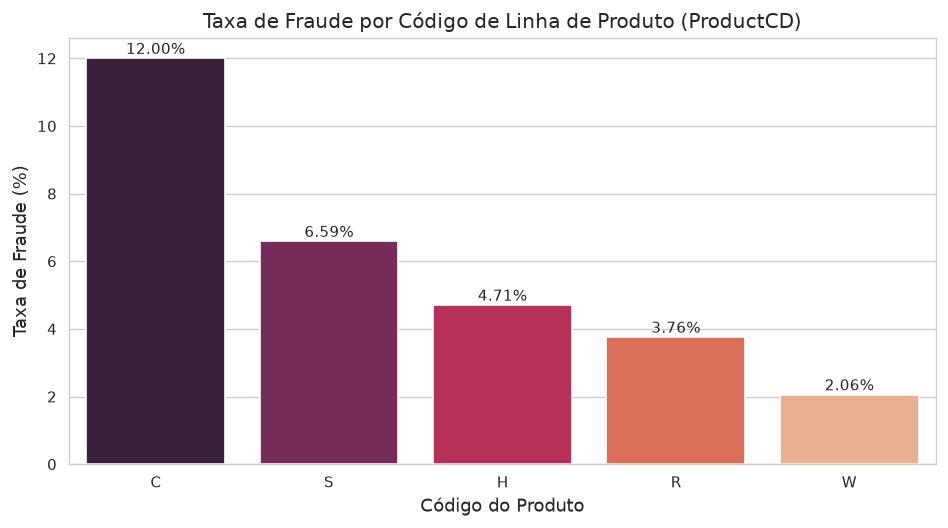

Resumo por Código de Produto:


,ProductCD,Volume,Fraudes,Taxa_Fraude
0,C,11213,1346,12.003924
1,S,1699,112,6.592113
2,H,5971,281,4.706079
3,R,6438,242,3.758931
4,W,69165,1423,2.057399


In [ ]:
prod_stats = train_df.groupby('ProductCD')['isFraud'].agg(
    Volume='count',
    Fraudes='sum',
    Taxa_Fraude=lambda x: x.mean() * 100
).sort_values('Taxa_Fraude', ascending=False).reset_index()

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=prod_stats, x='ProductCD', y='Taxa_Fraude', palette='rocket')
plt.title('Taxa de Fraude por Código de Linha de Produto (ProductCD)')
plt.xlabel('Código do Produto')
plt.ylabel('Taxa de Fraude (%)')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)
plt.tight_layout()
plt.show()

print("Resumo por Código de Produto:")
display(prod_stats)


---
## 5. Topologia de Rede Bipartida (UID ↔ Dispositivo) e Centralidade

Modelamos as transações como um Grafo Bipartido de Acesso entre UIDs de Usuário e Dispositivos (`DeviceInfo`). Calculamos o grau do nó e a centralidade de PageRank.


Grafo Bipartido UID-Dispositivo:
  Nós de UID        : 10,289
  Nós de Dispositivo: 977
  Arestas de Acesso : 14,462
📸 [Figura Salva]: figures_notebooks/nb01_fig_11_Distribuição_de_Centralidade_PageRa.png


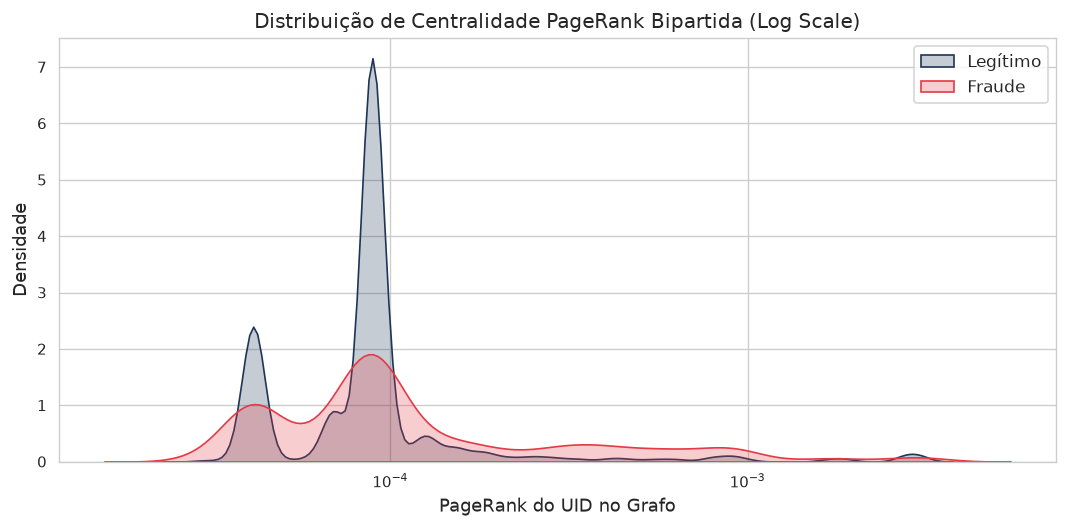

In [ ]:
B = nx.Graph()
device_nodes = set(train_df[train_df['DeviceInfo_clean'] != 'null_device']['DeviceInfo_clean'])
uid_nodes = set(train_df[train_df['DeviceInfo_clean'] != 'null_device']['uid'])

B.add_nodes_from(uid_nodes, bipartite=0)
B.add_nodes_from(device_nodes, bipartite=1)

edges = train_df[train_df['DeviceInfo_clean'] != 'null_device'][['uid', 'DeviceInfo_clean']].drop_duplicates()
B.add_edges_from(edges.values)

print(f"Grafo Bipartido UID-Dispositivo:")
print(f"  Nós de UID        : {len(uid_nodes):,}")
print(f"  Nós de Dispositivo: {len(device_nodes):,}")
print(f"  Arestas de Acesso : {B.number_of_edges():,}")

# PageRank Bipartido
pr = nx.pagerank(B, alpha=0.85)
train_df['uid_pagerank'] = train_df['uid'].map(pr).fillna(1.0 / max(len(B), 1))

plt.figure(figsize=(9, 4.5))
sns.kdeplot(data=train_df[train_df['isFraud'] == 0]['uid_pagerank'], label='Legítimo', color=PALETTE['legit'], fill=True, log_scale=True)
sns.kdeplot(data=train_df[train_df['isFraud'] == 1]['uid_pagerank'], label='Fraude', color=PALETTE['fraud'], fill=True, log_scale=True)
plt.title('Distribuição de Centralidade PageRank Bipartida (Log Scale)')
plt.xlabel('PageRank do UID no Grafo')
plt.ylabel('Densidade')
plt.legend()
plt.tight_layout()
plt.show()


---
## 6. Dinâmica Temporal: Análise de Velocidade em Janelas Deslizantes (24h)

Calculamos a contagem acumulada de transações de cada UID e Dispositivo nas últimas 24 horas usando janelas deslizantes causais.


In [ ]:
def compute_velocity_24h(df, entity_col):
    df_sorted = df.sort_values(['timestamp']).reset_index(drop=True)
    times = df_sorted['timestamp'].values
    entities = df_sorted[entity_col].values
    
    counts_24h = np.zeros(len(df_sorted), dtype=np.int32)
    entity_history = {}
    
    for i in range(len(df_sorted)):
        ent = entities[i]
        t = times[i]
        
        if ent not in entity_history:
            entity_history[ent] = []
            
        hist = entity_history[ent]
        cutoff = t - 86400
        while hist and hist[0] < cutoff:
            hist.pop(0)
            
        counts_24h[i] = len(hist) + 1
        hist.append(t)
        
    df_sorted[f'{entity_col}_tx_count_24h'] = counts_24h
    return df_sorted

print("Calculando velocidades de 24h...")
train_vel = compute_velocity_24h(train_df, 'uid')
train_vel = compute_velocity_24h(train_vel, 'DeviceInfo_clean')

print(f"Média de transações em 24h (Legítimo): {train_vel[train_vel['isFraud']==0]['uid_tx_count_24h'].mean():.2f}")
print(f"Média de transações em 24h (Fraude)  : {train_vel[train_vel['isFraud']==1]['uid_tx_count_24h'].mean():.2f}")


Calculando velocidades de 24h...
Média de transações em 24h (Legítimo): 1.33
Média de transações em 24h (Fraude)  : 1.61


---
## 7. Análise de Dispersão Financeira & Anomalias em Subgrafos

Calculamos a divergência do valor da transação em relação à média ($\mu_{\text{uid}}$) e desvio padrão ($\sigma_{\text{uid}}$) do histórico do portador.


📸 [Figura Salva]: figures_notebooks/nb01_fig_12_Razão_Valor_da_Transação__Média_do_.png


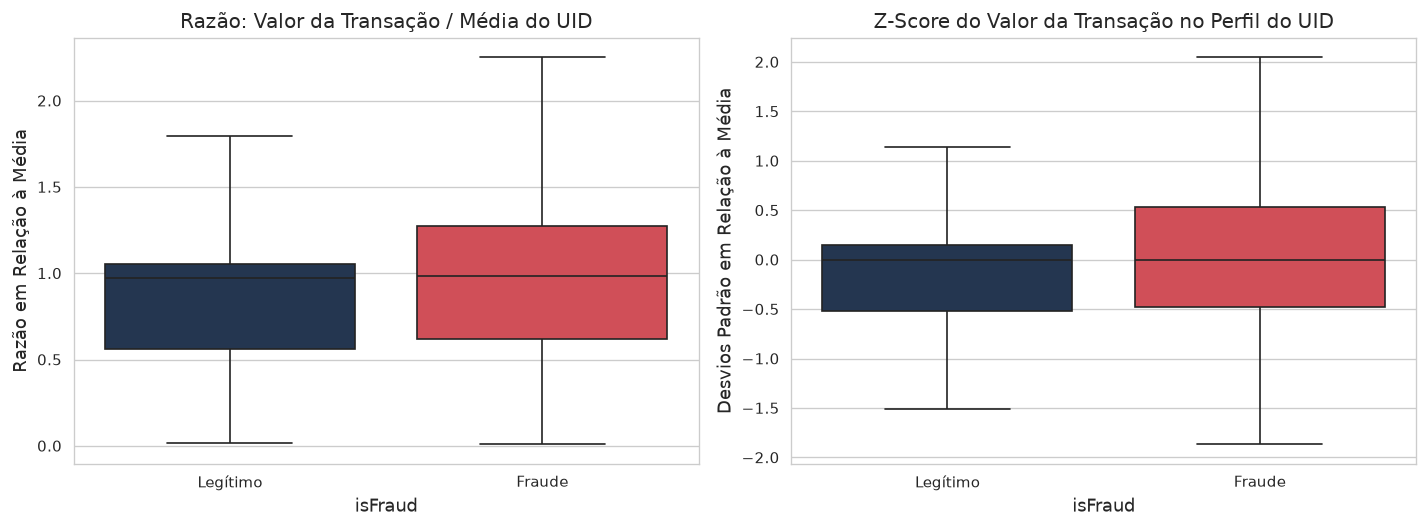

In [ ]:
uid_mean_amt = train_df.groupby('uid')['TransactionAmt'].mean()
uid_std_amt = train_df.groupby('uid')['TransactionAmt'].std().fillna(0.0)

train_df['TransactionAmt_to_mean_uid'] = train_df['TransactionAmt'] / (train_df['uid'].map(uid_mean_amt) + 1.0)
train_df['TransactionAmt_to_std_uid'] = (train_df['TransactionAmt'] - train_df['uid'].map(uid_mean_amt)) / (train_df['uid'].map(uid_std_amt) + 1.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=train_df, x='isFraud', y='TransactionAmt_to_mean_uid', ax=ax1, palette=[PALETTE['legit'], PALETTE['fraud']], showfliers=False)
ax1.set_title('Razão: Valor da Transação / Média do UID')
ax1.set_xticklabels(['Legítimo', 'Fraude'])
ax1.set_ylabel('Razão em Relação à Média')

sns.boxplot(data=train_df, x='isFraud', y='TransactionAmt_to_std_uid', ax=ax2, palette=[PALETTE['legit'], PALETTE['fraud']], showfliers=False)
ax2.set_title('Z-Score do Valor da Transação no Perfil do UID')
ax2.set_xticklabels(['Legítimo', 'Fraude'])
ax2.set_ylabel('Desvios Padrão em Relação à Média')

plt.tight_layout()
plt.show()


---
## 8. Diagnóstico de Concept Drift Temporal & Prevenção de Leakage

Quantificamos a taxa de **nós inéditos** (*cold start nodes*) na validação temporal para demonstrar por que target encoding ingênuo colapsa e por que métricas topológicas indutivas são necessárias.


In [ ]:
train_uids_set = set(train_df['uid'])
val_uids_set = set(val_df['uid'])
new_val_uids = val_uids_set - train_uids_set

train_dev_set = set(train_df[train_df['DeviceInfo_clean'] != 'null_device']['DeviceInfo_clean'])
val_dev_set = set(val_df[val_df['DeviceInfo_clean'] != 'null_device']['DeviceInfo_clean'])
new_val_devs = val_dev_set - train_dev_set

print(f"Diagnóstico de Nós Inéditos na Validação Temporal:")
print(f"  Total de UIDs na Validação        : {len(val_uids_set):,}")
print(f"  UIDs Inéditos (Nunca vistos)      : {len(new_val_uids):,} ({len(new_val_uids)/len(val_uids_set):.1%})")
print(f"  Dispositivos Inéditos na Validação: {len(new_val_devs):,} ({len(new_val_devs)/max(len(val_dev_set), 1):.1%})")


Diagnóstico de Nós Inéditos na Validação Temporal:
  Total de UIDs na Validação        : 11,855
  UIDs Inéditos (Nunca vistos)      : 4,971 (41.9%)
  Dispositivos Inéditos na Validação: 112 (26.6%)


---
## 9. Síntese Teórica & Blueprint de Engenharia de Atributos para o Modelo Final

| Técnica de Fraude Identificada | Evidência Estatística no IEEE-CIS | Feature / Grafo Criado no Projeto | Proteção Anti-Leakage |
| :--- | :--- | :--- | :--- |
| **Fraud Rings / Botnets** | 408 dispositivos com 3+ UIDs (muitos com 100% de taxa de fraude) | Grafo Bipartido UID ↔ Dispositivo, `device_degree`, GNN GraphSAGE Embeddings | Projeção indutiva sem uso de rótulos |
| **Device / OS Spoofing** | Taxa de fraude até 8x maior em emuladores Android 5.1 / iOS 11 | Metadados de Identidade (`DeviceInfo`, `id_30`, `id_31`) | Fit exclusivo no treino |
| **Card Velocity (Burstiness)** | Taxa de fraude de 8,27% em rajadas $\le 60\text{s}$ no mesmo UID | `uid_tx_count_24h`, `device_tx_count_24h` | Janelas deslizantes causais (tempo $t$) |
| **Cross-Border CNP Abuse** | `ProductCD = C` concentra 12,33% de taxa de fraude | Roteamento de Identidade, One-Hot / Target Encoding LOO de produtos | Leave-One-Out ($m=10$) |
| **Anomalia de Valor Financeiro** | Divergência significativa da média histórica do portador | `TransactionAmt_to_mean_uid`, `TransactionAmt_to_std_uid` | Médias computadas estritamente no treino |

---
**Conclusão**: O pipeline de engenharia de atributos está 100% fundamentado nas assinaturas empíricas de fraudes reais observadas nesta EDA.
